In [1]:
import json
import sqlite3

import pandas as pd

conn = sqlite3.connect("../data/happiness_raw.db")
raw = pd.read_sql_query("SELECT * FROM raw_records", conn)

print(raw.shape)
print(raw.groupby("year").size())
raw.head()

(782, 7)
year
2015    158
2016    157
2017    155
2018    156
2019    156
dtype: int64


,record_id,year,source_file,kafka_partition,kafka_offset,kafka_ts,payload
0,2015-4,2015,2015.csv,2,0,1794769254624,"{""Country"": ""Norway"", ""Region"": ""Western Europ..."
1,2015-6,2015,2015.csv,2,1,1794769254625,"{""Country"": ""Finland"", ""Region"": ""Western Euro..."
2,2015-8,2015,2015.csv,2,2,1794769254625,"{""Country"": ""Sweden"", ""Region"": ""Western Europ..."
3,2015-9,2015,2015.csv,2,3,1794769254625,"{""Country"": ""New Zealand"", ""Region"": ""Australi..."
4,2015-12,2015,2015.csv,2,4,1794769254625,"{""Country"": ""Costa Rica"", ""Region"": ""Latin Ame..."


In [2]:
ejemplo = raw.iloc[0]
print("Metadatos:", {k: v for k, v in ejemplo.items() if k != "payload"})
print("\nCampos originales:")
print(json.dumps(json.loads(ejemplo["payload"]), indent=2))

Metadatos: {'record_id': '2015-4', 'year': np.int64(2015), 'source_file': '2015.csv', 'kafka_partition': np.int64(2), 'kafka_offset': np.int64(0), 'kafka_ts': np.int64(1794769254624)}

Campos originales:
{
  "Country": "Norway",
  "Region": "Western Europe",
  "Happiness Rank": 4,
  "Happiness Score": 7.522,
  "Standard Error": 0.0388,
  "Economy (GDP per Capita)": 1.459,
  "Family": 1.33095,
  "Health (Life Expectancy)": 0.88521,
  "Freedom": 0.66973,
  "Trust (Government Corruption)": 0.36503,
  "Generosity": 0.34699,
  "Dystopia Residual": 2.46531
}


In [3]:
por_anio = {}
for year, g in raw.groupby("year"):
    por_anio[year] = pd.DataFrame([json.loads(p) for p in g["payload"]])

for year, df in por_anio.items():
    print(f"--- {year}: {df.shape}")
    print(df.dtypes.to_string())
    print("nulos:", df.isna().sum()[lambda s: s > 0].to_dict())
    print()

--- 2015: (158, 12)
Country                              str
Region                               str
Happiness Rank                     int64
Happiness Score                  float64
Standard Error                   float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Generosity                       float64
Dystopia Residual                float64
nulos: {}

--- 2016: (157, 13)
Country                              str
Region                               str
Happiness Rank                     int64
Happiness Score                  float64
Lower Confidence Interval        float64
Upper Confidence Interval        float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Genero

In [4]:
cols = {y: set(df.columns) for y, df in por_anio.items()}
comunes = set.intersection(*cols.values())
print("Comunes a todos los años:", sorted(comunes))
for y, c in cols.items():
    print(y, "no comunes:", sorted(c - comunes))

presencia = (pd.DataFrame({y: pd.Series(1, index=list(c)) for y, c in cols.items()})
             .fillna(0).astype(int).sort_index())
presencia

Comunes a todos los años: ['Generosity']
2015 no comunes: ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Region', 'Standard Error', 'Trust (Government Corruption)']
2016 no comunes: ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Lower Confidence Interval', 'Region', 'Trust (Government Corruption)', 'Upper Confidence Interval']
2017 no comunes: ['Country', 'Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Happiness.Rank', 'Happiness.Score', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Whisker.high', 'Whisker.low']
2018 no comunes: ['Country or region', 'Freedom to make life choices', 'GDP per capita', 'Healthy life expectancy', 'Overall rank', 'Perceptions of corruption', 'Score', 'Social support']
2019 no comunes: ['Country or region', 'Freedom to ma

,2015,2016,2017,2018,2019
Country,1,1,1,0,0
Country or region,0,0,0,1,1
Dystopia Residual,1,1,0,0,0
Dystopia.Residual,0,0,1,0,0
Economy (GDP per Capita),1,1,0,0,0
Economy..GDP.per.Capita.,0,0,1,0,0
Family,1,1,1,0,0
Freedom,1,1,1,0,0
Freedom to make life choices,0,0,0,1,1
GDP per capita,0,0,0,1,1


In [5]:
resumen = pd.DataFrame({
    y: {"filas": df.shape[0], "columnas": df.shape[1],
        "filas_con_nulos": int(df.isna().any(axis=1).sum())}
    for y, df in por_anio.items()
}).T
print(resumen)

for y, df in por_anio.items():
    n = df.isna().sum()
    n = n[n > 0]
    if len(n):
        print(f"\n{y}: nulos por columna ->", n.to_dict())
        print(df[df.isna().any(axis=1)].to_string())

tipos = pd.DataFrame({y: df.dtypes.astype(str) for y, df in por_anio.items()})
print("\nColumnas cuyo tipo cambia entre años:")
print(tipos[tipos.nunique(axis=1) > 1])

      filas  columnas  filas_con_nulos
2015    158        12                0
2016    157        13                0
2017    155        12                0
2018    156         9                1
2019    156         9                0

2018: nulos por columna -> {'Perceptions of corruption': 1}
     Overall rank     Country or region  Score  GDP per capita  Social support  Healthy life expectancy  Freedom to make life choices  Generosity  Perceptions of corruption
112            20  United Arab Emirates  6.774           2.096           0.776                     0.67                         0.284       0.186                        NaN

Columnas cuyo tipo cambia entre años:
Empty DataFrame
Columns: [2015, 2016, 2017, 2018, 2019]
Index: []


## Decisión de integración

Se apilan los cinco años en un único conjunto en formato largo (una fila por país y año),
con una columna `year`. Los nombres de columnas se unifican con una tabla de equivalencias.

**Columnas que se conservan:** country, year, score, gdp, social_support, life_expectancy,
freedom, corruption, generosity.

**Columnas que se descartan:**
- `Happiness Rank` / `Overall rank`: es el propio score expresado como posición.
- `Standard Error`, `Lower/Upper Confidence Interval`, `Whisker.high/low`: miden la
  incertidumbre del score y cada una existe en un solo año.
- `Dystopia Residual`: solo existe en 2015-2017.
- `Region`: solo existe en 2015-2016.

**Limitaciones:** (1) `Family` y `Social support` se tratan como la misma variable por su
nombre y posición, sin confirmación oficial; (2) un mismo país aparece varias veces, lo que
afecta la separación entrenamiento/prueba; (3) se pierde `Region` para 2017-2019.

In [6]:
EQUIVALENCIAS = {
    "country": ["Country", "Country or region"],
    "score": ["Happiness Score", "Happiness.Score", "Score"],
    "gdp": ["Economy (GDP per Capita)", "Economy..GDP.per.Capita.", "GDP per capita"],
    "social_support": ["Family", "Social support"],
    "life_expectancy": ["Health (Life Expectancy)", "Health..Life.Expectancy.",
                        "Healthy life expectancy"],
    "freedom": ["Freedom", "Freedom to make life choices"],
    "corruption": ["Trust (Government Corruption)", "Trust..Government.Corruption.",
                   "Perceptions of corruption"],
    "generosity": ["Generosity"],
}
RENOMBRAR = {viejo: nuevo for nuevo, viejos in EQUIVALENCIAS.items() for viejo in viejos}

partes = []
for year, df in por_anio.items():
    d = df.rename(columns=RENOMBRAR)[list(EQUIVALENCIAS)].copy()  # KeyError si falta alguna
    d.insert(1, "year", year)
    partes.append(d)

datos = pd.concat(partes, ignore_index=True)

print(datos.shape)
print(datos.groupby("year").size().to_dict())
print("duplicados país-año:", datos.duplicated(["country", "year"]).sum())
print(datos.dtypes)
print(datos.isna().sum().to_dict())
datos.head()

(782, 9)
{2015: 158, 2016: 157, 2017: 155, 2018: 156, 2019: 156}
duplicados país-año: 0
country                str
year                 int64
score              float64
gdp                float64
social_support     float64
life_expectancy    float64
freedom            float64
corruption         float64
generosity         float64
dtype: object
{'country': 0, 'year': 0, 'score': 0, 'gdp': 0, 'social_support': 0, 'life_expectancy': 0, 'freedom': 0, 'corruption': 1, 'generosity': 0}


,country,year,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
0,Norway,2015,7.522,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699
1,Finland,2015,7.406,1.29025,1.31826,0.88911,0.64169,0.41372,0.23351
2,Sweden,2015,7.364,1.33171,1.28907,0.91087,0.65980,0.43844,0.36262
3,New Zealand,2015,7.286,1.25018,1.31967,0.90837,0.63938,0.42922,0.47501
4,Costa Rica,2015,7.226,0.95578,1.23788,0.86027,0.63376,0.10583,0.25497


In [7]:
from difflib import SequenceMatcher

anios_por_pais = datos.groupby("country")["year"].agg(["nunique", "min", "max"])
print("Países según en cuántos años aparecen:")
print(anios_por_pais["nunique"].value_counts().sort_index())
print("Total de países distintos:", datos["country"].nunique())

incompletos = anios_por_pais[anios_por_pais["nunique"] < 5].sort_values("min")
display(incompletos)

# Posibles nombres distintos de un mismo país: nunca coinciden en un año
# y se parecen entre sí
años = datos.groupby("country")["year"].apply(set)
nombres = list(incompletos.index)
print("\nPosibles variantes de nombre:")
for i, a in enumerate(nombres):
    for b in nombres[i + 1:]:
        if años[a].isdisjoint(años[b]):
            la, lb = a.lower(), b.lower()
            r = SequenceMatcher(None, la, lb).ratio()
            if r > 0.6 or la in lb or lb in la:
                print(f"{a!r} {sorted(años[a])}  <->  {b!r} {sorted(años[b])}  similitud={r:.2f}")

Países según en cuántos años aparecen:
nunique
1      9
2      4
3      4
4     12
5    141
Name: count, dtype: int64
Total de países distintos: 170


,nunique,min,max
country,,,
Angola,4,2015,2018
Central African Republic,4,2015,2019
Comoros,3,2015,2019
Djibouti,1,2015,2015
Hong Kong,4,2015,2019
Macedonia,4,2015,2018
Lesotho,4,2015,2019
Laos,4,2015,2019
North Cyprus,3,2015,2017



Posibles variantes de nombre:
'Hong Kong' [2015, 2016, 2018, 2019]  <->  'Hong Kong S.A.R., China' [2017]  similitud=0.56
'Macedonia' [2015, 2016, 2017, 2018]  <->  'North Macedonia' [2019]  similitud=0.75
'North Cyprus' [2015, 2016, 2017]  <->  'Northern Cyprus' [2018, 2019]  similitud=0.89
'Trinidad and Tobago' [2015, 2016, 2017]  <->  'Trinidad & Tobago' [2018, 2019]  similitud=0.89
'Taiwan' [2015, 2016, 2018, 2019]  <->  'Taiwan Province of China' [2017]  similitud=0.40
'Somaliland region' [2015]  <->  'Somaliland Region' [2016]  similitud=1.00


## Valores faltantes

Solo hay un nulo: `corruption` de United Arab Emirates en 2018. No se elimina la fila
(se perdería un registro con el resto de variables completas). Se imputará con la mediana
calculada **solo con los datos de entrenamiento**, dentro del pipeline del modelo, para que
la información del conjunto de prueba no influya en el entrenamiento.

In [8]:
CORRECCION_PAISES = {
    "Somaliland region": "Somaliland Region",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "North Cyprus": "Northern Cyprus",
    "Macedonia": "North Macedonia",
}

datos["country"] = datos["country"].str.strip().replace(CORRECCION_PAISES)

print("Países distintos:", datos["country"].nunique())
print("Duplicados país-año:", datos.duplicated(["country", "year"]).sum())
print(datos.groupby("country")["year"].nunique().value_counts().sort_index())

Países distintos: 164
Duplicados país-año: 0
year
1      4
2      3
3      2
4      9
5    146
Name: count, dtype: int64


## Inconsistencias en los nombres de países

Seis países aparecen con nombres distintos según el año (por ejemplo, `Macedonia` y
`North Macedonia`, o `Taiwan` y `Taiwan Province of China`). Sin corregirlo, cada variante
se contaría como un país distinto (170 en lugar de 164). Se unifican con un diccionario y
se comprueba que no aparezcan duplicados país-año.

Además, la cobertura no es constante: de los 164 países, 146 aparecen en los cinco años y
18 en menos (por ejemplo, Oman y Djibouti solo en 2015, Puerto Rico solo en 2016, Gambia
solo en 2019). No se imputan países ausentes: simplemente no aportan filas en esos años.

Estadísticas descriptivas y outliers

In [9]:
VARIABLES = ["score", "gdp", "social_support", "life_expectancy",
             "freedom", "corruption", "generosity"]
FEATURES = VARIABLES[1:]   # todas menos el objetivo

desc = datos[VARIABLES].describe().T
desc["nulos"] = datos[VARIABLES].isna().sum()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,nulos
score,782.0,5.379,1.127,2.693,4.510,5.322,6.190,7.769,0
gdp,782.0,0.916,0.407,0.000,0.606,0.982,1.236,2.096,0
social_support,782.0,1.078,0.330,0.000,0.869,1.125,1.327,1.644,0
life_expectancy,782.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141,0
freedom,782.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724,0
corruption,781.0,0.125,0.106,0.000,0.054,0.091,0.156,0.552,1
generosity,782.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838,0


In [10]:
datos.groupby("year")[VARIABLES].mean().round(3)

,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.143,0.237
2016,5.382,0.954,0.794,0.558,0.371,0.138,0.243
2017,5.354,0.985,1.189,0.551,0.409,0.123,0.247
2018,5.376,0.891,1.213,0.597,0.455,0.112,0.181
2019,5.407,0.905,1.209,0.725,0.393,0.111,0.185


In [11]:
print("Valores iguales a 0 por variable:")
print((datos[FEATURES] == 0).sum().to_string())


def contar_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()


print("\nOutliers por regla del IQR (1.5 × IQR):")
print(datos[VARIABLES].apply(contar_outliers).to_string())

Valores iguales a 0 por variable:
gdp                5
social_support     5
life_expectancy    5
freedom            5
corruption         6
generosity         5

Outliers por regla del IQR (1.5 × IQR):
score               0
gdp                 0
social_support     10
life_expectancy     0
freedom             0
corruption         67
generosity         17


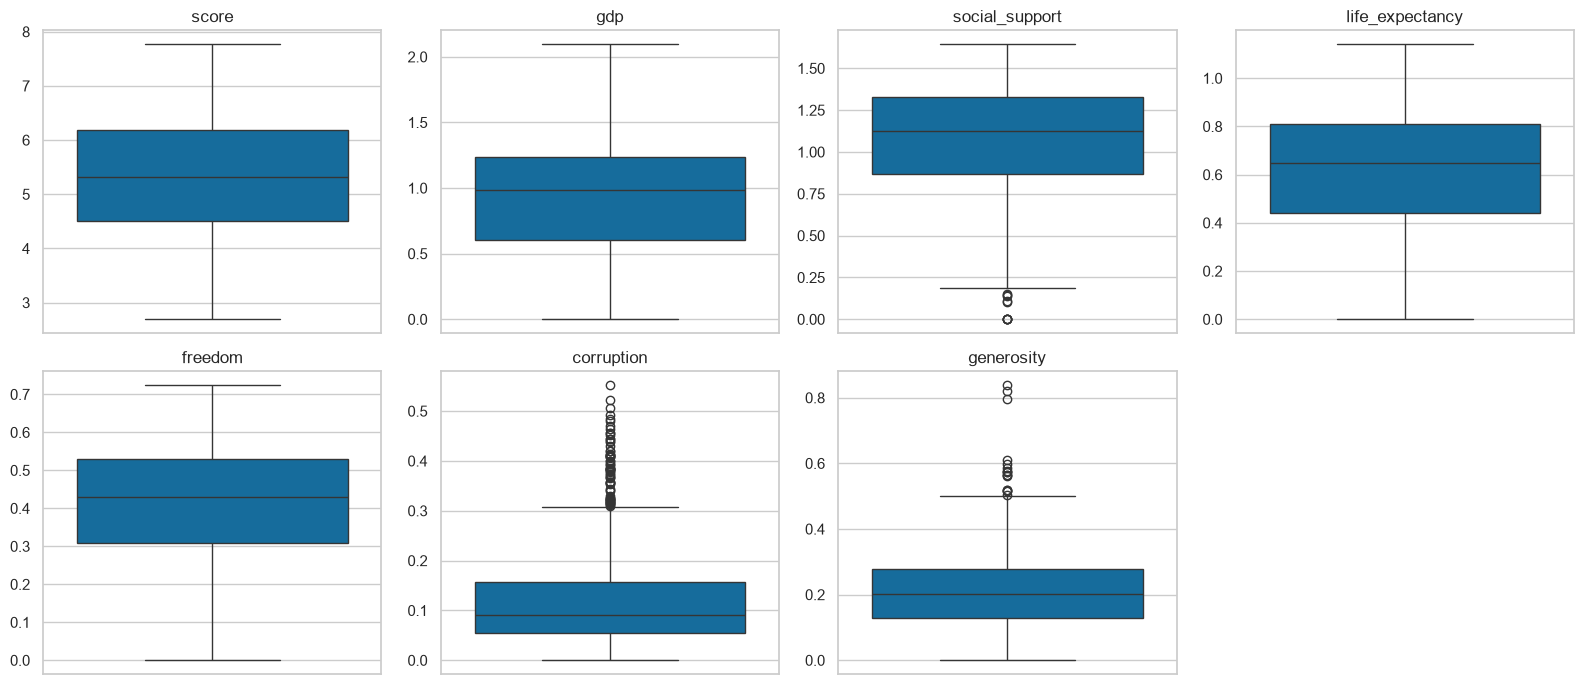

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), VARIABLES):
    sns.boxplot(y=datos[col], ax=ax, color="#0072B2")
    ax.set_title(col)
    ax.set_ylabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

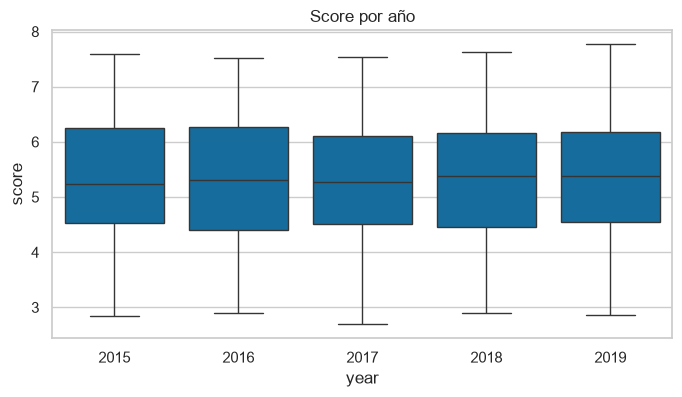

In [13]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=datos, x="year", y="score", color="#0072B2")
plt.title("Score por año")
plt.show()

## Diferencias entre años

El score medio es estable entre ediciones (5.35 a 5.41), pero varias variables cambian de
nivel: `social_support` baja a 0.79 en 2016 y sube a 1.19 en 2017; `life_expectancy` salta a
0.73 en 2019; `generosity` cae a 0.18 en 2018; `corruption` desciende de forma continua.
Hipótesis: cambios metodológicos entre ediciones (no verificada). Se tendrá en cuenta al
preparar las variables.

## Outliers

Por la regla del IQR hay 10 outliers en `social_support` (cola baja), 67 en `corruption` y
17 en `generosity` (cola alta). Son valores plausibles en variables sesgadas a la derecha,
no errores evidentes: se conservan, y se evaluará su efecto en el modelo.

In [14]:
con_ceros = datos[(datos[FEATURES] == 0).any(axis=1)]
print("Filas con algún cero:", len(con_ceros))
print("Ceros por fila:", (con_ceros[FEATURES] == 0).sum(axis=1).value_counts().to_dict())
con_ceros[["country", "year", "score"] + FEATURES]

Filas con algún cero: 30
Ceros por fila: {1: 29, 2: 1}


,country,year,score,gdp,social_support,life_expectancy,freedom,corruption,generosity
43,Sierra Leone,2015,4.507,0.330240,0.955710,0.000000,0.408400,0.087860,0.214880
55,Central African Republic,2015,3.678,0.078500,0.000000,0.066990,0.488790,0.082890,0.238350
76,Indonesia,2015,5.399,0.828270,1.087080,0.637930,0.466110,0.000000,0.515350
134,Greece,2015,4.857,1.154060,0.929330,0.882130,0.076990,0.013970,0.000000
140,Iraq,2015,4.677,0.985490,0.818890,0.602370,0.000000,0.137880,0.179220
143,Congo (Kinshasa),2015,4.517,0.000000,1.001200,0.098060,0.226050,0.076250,0.248340
183,Bosnia and Herzegovina,2016,5.163,0.933830,0.643670,0.707660,0.095110,0.000000,0.298890
188,Greece,2016,5.033,1.248860,0.754730,0.800290,0.058220,0.041270,0.000000
208,Togo,2016,3.303,0.281230,0.000000,0.248110,0.346780,0.115870,0.175170
231,Somalia,2016,5.440,0.000000,0.336130,0.114660,0.567780,0.311800,0.272250


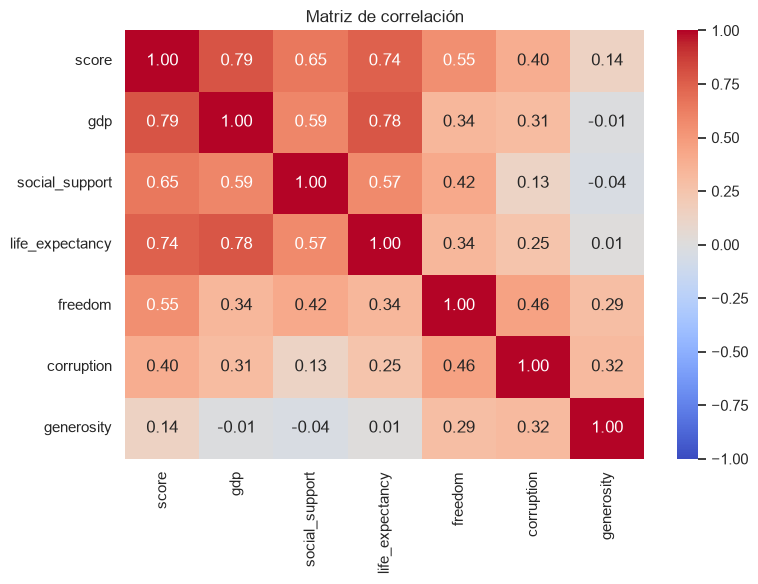

Pares de variables explicativas con |correlación| > 0.6:
[('gdp', 'life_expectancy', np.float64(0.78))]

Correlación con el score, por año:


,2015,2016,2017,2018,2019
gdp,0.781,0.790,0.812,0.802,0.794
social_support,0.741,0.739,0.753,0.746,0.777
life_expectancy,0.724,0.765,0.782,0.776,0.780
freedom,0.568,0.567,0.570,0.544,0.567
corruption,0.395,0.402,0.429,0.405,0.386
generosity,0.180,0.157,0.155,0.136,0.076


In [15]:
corr = datos[VARIABLES].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

print("Pares de variables explicativas con |correlación| > 0.6:")
print([(a, b, round(corr.loc[a, b], 2))
       for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
       if abs(corr.loc[a, b]) > 0.6])

print("\nCorrelación con el score, por año:")
pd.DataFrame({y: g[FEATURES].corrwith(g["score"])
              for y, g in datos.groupby("year")}).round(3)

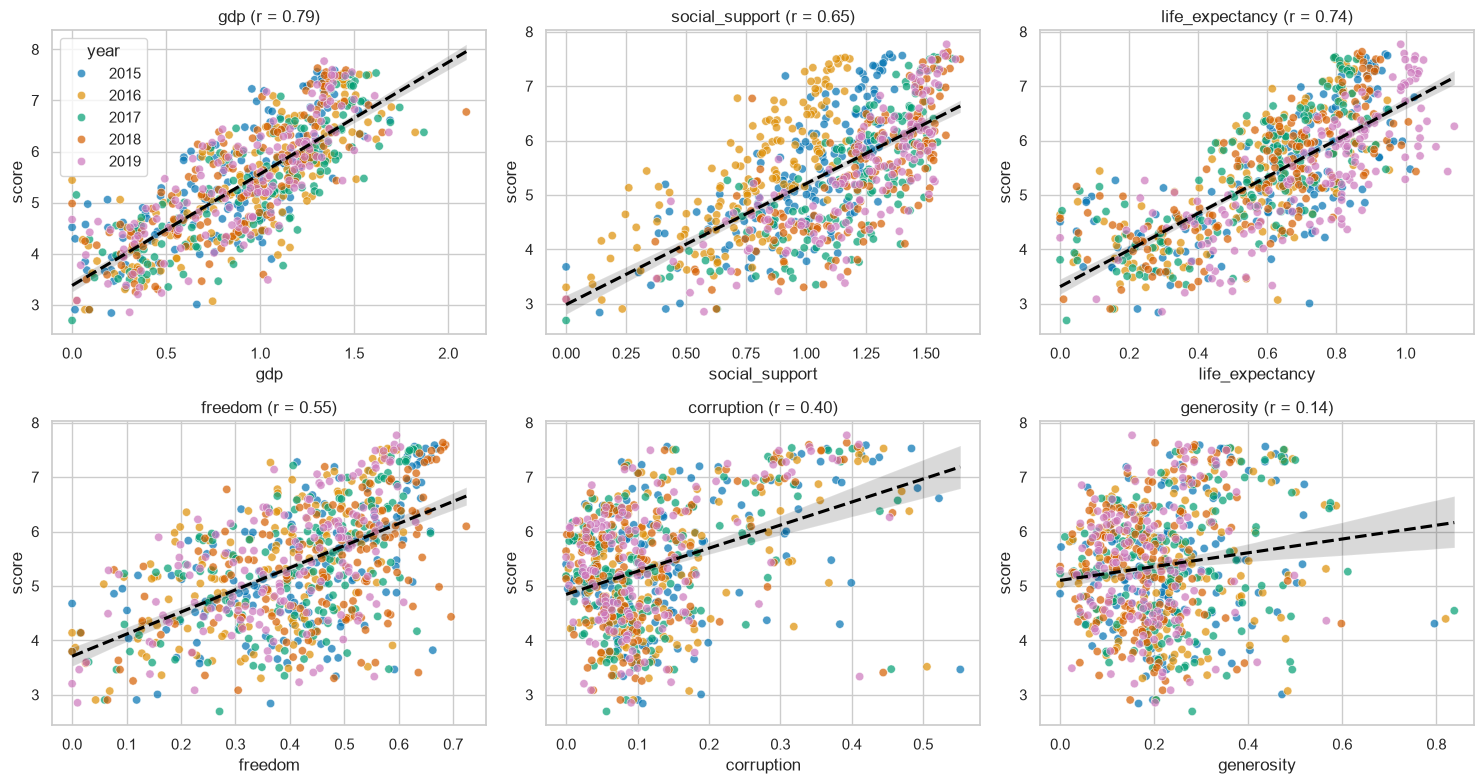

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.scatterplot(data=datos, x=col, y="score", hue="year", palette="colorblind",
                    alpha=0.7, ax=ax, legend=(col == FEATURES[0]))
    sns.regplot(data=datos.dropna(subset=[col]), x=col, y="score", scatter=False,
                color="black", line_kws={"linestyle": "--"}, ax=ax)
    ax.set_title(f"{col} (r = {datos[col].corr(datos['score']):.2f})")
plt.tight_layout()
plt.show()